# Week 6 — Plant Leaf Disease Detection with ResNet-18
**Name:Aman Riaz**


**Introduction to Applied AI — Lab 6: Applied Computer Vision in Your Own Domain**

**Problem:** classify pepper, potato and tomato leaves as **healthy** or **diseased** using
transfer learning (ImageNet-pretrained ResNet-18), as a step towards smart-agriculture tools.

**Dataset:** PlantVillage (Kaggle: `emmarex/plantdisease`), 15 class folders merged into 2 classes.

**Pipeline:** audit → leakage check → grouped split → weighted training → test once →
threshold for 95% recall → Grad-CAM shortcut check → README.

In [1]:
# ============ CHANGE ONLY THIS CELL FOR YOUR OWN DATASET ============
DATA_ROOT = '/kaggle/input/datasets/emmarex/plantdisease/PlantVillage'   # folder with the 15 class folders
TRAIN_DIR = DATA_ROOT        # folder whose subfolders are the 15 class folders
TEST_DIR = None              # PlantVillage has no test folder -> the code carves a grouped test set
GRAYSCALE = False            # leaf photos are colour, and colour is part of the disease evidence
IMG_SIZE = 224
BACKBONE = 'resnet18'
# File names look like '...___GHLB_PS Leaf 23.7 Day 13.jpg' or '...___JR_B.Spot 8964.JPG'.
# Group = leaf id: drop the shot number ('.7') and the day ('Day 13') so all photos
# of the same leaf share one group.
GROUP_PATTERN = r'___(.+?)(?:\.\d+)?(?: Day \d+)?\.(?:jpg|jpeg|png|JPG|JPEG|PNG)$'
BINARY = True                # True: merge the 15 folders into 'healthy' vs 'diseased'
POSITIVE = 'diseased'        # the class a farmer must not miss
TARGET_RECALL = 0.95
# ======================================================================

 **Configuration**
This is the only cell that adapts the framework to my dataset. Key choices:
- `TEST_DIR = None` — PlantVillage has no test folder, so a grouped test set is carved later.
- `GRAYSCALE = False` — leaf colour (yellowing, browning) is part of the disease evidence.
- `GROUP_PATTERN` — extracts the leaf id from the file name, removing the shot number and
  the day, so all photos of the same leaf stay in one group.
- `BINARY = True`, `POSITIVE = 'diseased'`, `TARGET_RECALL = 0.95` — a farmer must not miss
  a diseased leaf.

In [2]:
import os
import re
import time
import copy
import hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             roc_auc_score, roc_curve)

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


In [3]:
def index_folder(folder):
    """One row per image: path, label, original class folder, file name, group id."""
    rows = []
    for cls in sorted(os.listdir(folder)):
        cdir = os.path.join(folder, cls)
        if not os.path.isdir(cdir):
            continue
        for f in sorted(os.listdir(cdir)):
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif')):
                if BINARY:
                    label = 'healthy' if 'healthy' in cls.lower() else 'diseased'
                else:
                    label = cls
                rows.append({'path': os.path.join(cdir, f), 'label': label,
                             'orig_class': cls, 'file': f})
    df = pd.DataFrame(rows)
    if GROUP_PATTERN:
        m = df['file'].str.extract(GROUP_PATTERN, expand=False)
        df['group'] = m.fillna(df['file'])          # no match: its own group
    else:
        df['group'] = df['file']
    return df

train_df = index_folder(TRAIN_DIR)
test_df = index_folder(TEST_DIR) if TEST_DIR else None
classes = sorted(train_df['label'].unique())

counts = train_df['label'].value_counts().reindex(classes)
print(counts.to_string())
print(f'Imbalance ratio (max / min): {counts.max() / counts.min():.1f}')
print(f'Images per group: {len(train_df) / train_df.group.nunique():.2f}')
print('\nOriginal 15 folders:')
print(train_df['orig_class'].value_counts().to_string())
print('\nGroup regex check:')
print(train_df[['file', 'group']].head(10).to_string())

label
diseased    17417
healthy      3221
Imbalance ratio (max / min): 5.4
Images per group: 1.02

Original 15 folders:
orig_class
Tomato__Tomato_YellowLeaf__Curl_Virus          3208
Tomato_Bacterial_spot                          2127
Tomato_Late_blight                             1909
Tomato_Septoria_leaf_spot                      1771
Tomato_Spider_mites_Two_spotted_spider_mite    1676
Tomato_healthy                                 1591
Pepper__bell___healthy                         1478
Tomato__Target_Spot                            1404
Potato___Early_blight                          1000
Potato___Late_blight                           1000
Tomato_Early_blight                            1000
Pepper__bell___Bacterial_spot                   997
Tomato_Leaf_Mold                                952
Tomato__Tomato_mosaic_virus                     373
Potato___healthy                                152

Group regex check:
                                                          file       

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
         w      h
min  256.0  256.0
50%  256.0  256.0
max  256.0  256.0
Colour modes: {'RGB': 300}


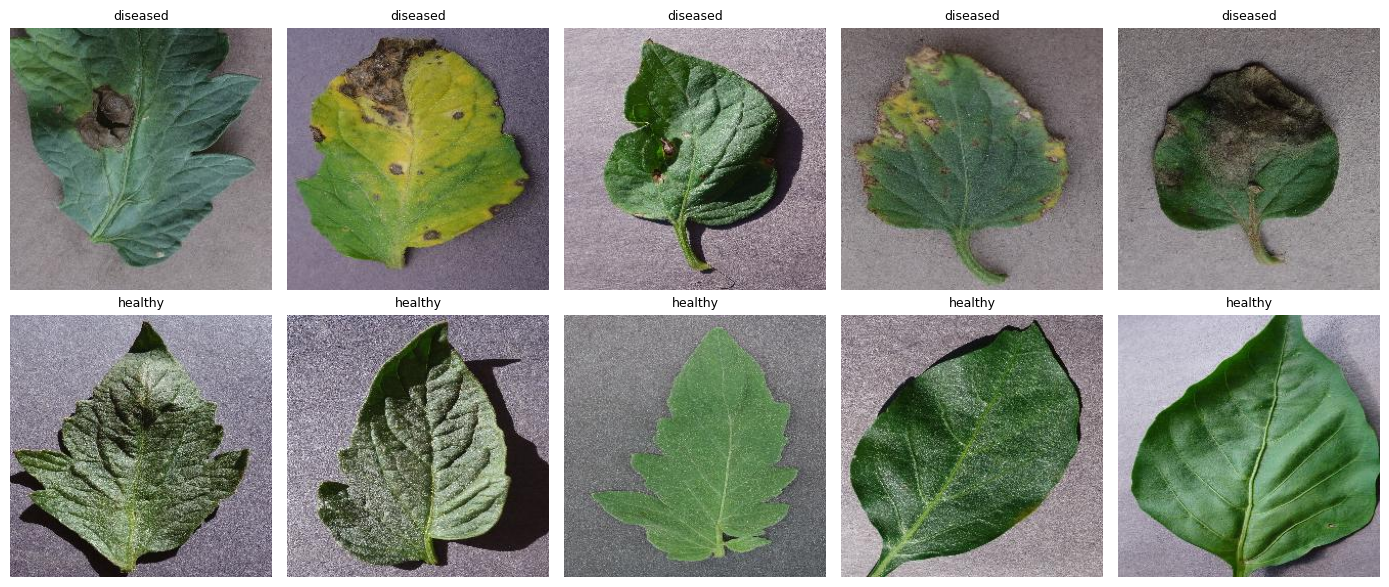

In [20]:
sample = train_df.sample(min(300, len(train_df)), random_state=0)
info = []
for p in sample['path']:
    with Image.open(p) as im:
        info.append({'w': im.size[0], 'h': im.size[1], 'mode': im.mode})
info = pd.DataFrame(info)
print(info.describe().round(0).loc[['min', '50%', 'max']])
print('Colour modes:', info['mode'].value_counts().to_dict())

fig, axes = plt.subplots(len(classes), 5, figsize=(14, 3 * len(classes)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes):
    paths = train_df[train_df.label == c]['path'].sample(5, random_state=1)
    for ax, p in zip(axes[r], paths):
        ax.imshow(Image.open(p).convert('RGB'))
        ax.set_title(c, fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

### Part 1 — Dataset audit

**Dataset:** PlantVillage (emmarex/plantdisease on Kaggle), 20,638 images in 15 class folders
(Pepper, Potato, Tomato). I merged the 15 folders into a binary task: **healthy vs diseased**.

**Class counts:** diseased 17,417 | healthy 3,221 → **imbalance ratio 5.4**.
A model that always predicts "diseased" would already be ~84% accurate, so accuracy is
not a useful metric here.

**Hidden imbalance:** the "healthy" class is mostly tomato (1,591) and pepper (1,478).
Potato___healthy has only **152** images, so the model has seen very few healthy potato leaves
and may learn "potato leaf → diseased".

**Image properties:** all 300 sampled images are **RGB, 256 × 256** — perfectly uniform, which
suggests controlled lab photography rather than field conditions.

**Data note:** the dataset ships two top-level folders (`PlantVillage` and `plantvillage`),
which look like duplicate copies. I used only `PlantVillage` to avoid counting images twice.

**First shortcut suspect — framing and background:** in the sample grid, all leaves lie on the
same grey-purple cloth background. The diseased leaves tend to be smaller in the frame, so more
background is visible, and some are photographed in brighter light. Several healthy leaves
(especially pepper) fill almost the whole frame and look darker green. The model could learn
"more background / smaller leaf / brighter image → diseased" instead of the lesions themselves.
I will check this with Grad-CAM in Part 6.

In [4]:
g = train_df.groupby('group').size().sort_values(ascending=False)
print('Groups with more than 1 image:', (g > 1).sum())
print(g.head(10).to_string())
print(train_df[train_df['group'] == g.index[0]][['orig_class', 'file']].to_string())

Groups with more than 1 image: 331
group
GHLB Leaf 2        16
GHLB_PS Leaf 1     15
GHLB Leaf 23       14
GHLB_PS Leaf 2     13
GHLB_PS Leaf 8     10
GHLB Leaf 1        10
GHLB_PS Leaf 23     9
GHLB_PS Leaf 24     9
GHLB_PS Leaf 26     9
GHLB Leaf 8         7
              orig_class                                                             file
7767  Tomato_Late_blight  01a68044-9c5b-4658-a944-6108c6862ce7___GHLB Leaf 2.1 Day 16.JPG
8074  Tomato_Late_blight  278c79c0-ebab-4c54-b573-d94a936e63e4___GHLB Leaf 2.3 Day 13.JPG
8195  Tomato_Late_blight    3a1a6b9e-2a68-421f-adbe-229baf8a6093___GHLB Leaf 2 Day 13.JPG
8221  Tomato_Late_blight     3e01dcb7-e660-4403-861a-59a44d572565___GHLB Leaf 2 Day 7.JPG
8416  Tomato_Late_blight   589aa880-2e56-4025-b997-6c495644302a___GHLB Leaf 2.1 Day 6.JPG
8442  Tomato_Late_blight     5c2e8475-ec0a-4566-af20-a4dedf3dc1c0___GHLB Leaf 2 Day 1.JPG
8602  Tomato_Late_blight  7525f169-671f-4ec6-95f2-5bb54b6fd14d___GHLB Leaf 2.4 Day 13.JPG
8606  Tomato_Late_b

In [5]:
def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

def fingerprint(path, n=32):
    """32 x 32 grayscale thumbnail, standardized: robust to resizing,
    recompression, and brightness changes."""
    with Image.open(path) as im:
        im.draft('L', (n * 4, n * 4))            # fast JPEG decode
        a = np.asarray(im.convert('L').resize((n, n)), dtype=np.float32)
    return ((a - a.mean()) / (a.std() + 1e-6)).flatten()

all_df = pd.concat([train_df.assign(split='train'),
                    test_df.assign(split='test')]) if TEST_DIR else train_df.copy()
all_df['md5'] = [md5(p) for p in all_df['path']]
exact = all_df[all_df.duplicated('md5', keep=False)]
print('Exact duplicate files:', len(exact))
print('Duplicate groups (sets of identical files):', exact['md5'].nunique())
if len(exact):
    print(exact.sort_values('md5')[['orig_class', 'file', 'md5']].head(20).to_string())
    conflict = exact.groupby('md5')['label'].nunique()
    print('Identical files with DIFFERENT labels:', (conflict > 1).sum())

Exact duplicate files: 28
Duplicate groups (sets of identical files): 14
               orig_class                                                                 file                               md5
8465   Tomato_Late_blight           5f21282c-e2ef-4c4a-ace1-b5701fe7effc___GHLB2 Leaf 8999.JPG  0e0dcd876f5b32cac9da836b2e783d91
9484   Tomato_Late_blight           e5d707cd-077c-43af-bda9-6138e516ff51___GHLB2 Leaf 8999.JPG  0e0dcd876f5b32cac9da836b2e783d91
7974   Tomato_Late_blight           1a69b38b-c4eb-42c4-9584-bcb14fb8db0c___GHLB2 Leaf 9011.JPG  1d87a50fa691cef6f476b20bb48cfaf8
8107   Tomato_Late_blight           2c47b891-3c97-48f1-a2cc-5aa53d3a1148___GHLB2 Leaf 9011.JPG  1d87a50fa691cef6f476b20bb48cfaf8
19566      Tomato_healthy            505465db-407b-4e0a-8110-7479dad5261c___GH_HL Leaf 389.JPG  2e53ad1ec3f810e2ff4c83400dc69ec9
19389      Tomato_healthy            37203047-d8ba-43f7-b31e-d496c41c569c___GH_HL Leaf 389.JPG  2e53ad1ec3f810e2ff4c83400dc69ec9
19383      Tomato_health

In [6]:
# Keep one copy of each byte-identical file
train_df['md5'] = all_df['md5'].values
before = len(train_df)
train_df = train_df.drop_duplicates('md5', keep='first').reset_index(drop=True)
print(f'Removed {before - len(train_df)} duplicate copies; {len(train_df)} images remain')

Removed 14 duplicate copies; 20624 images remain


In [7]:
# Validation split BY GROUP: no leaf appears in both train and val
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(train_df, train_df['label'],
                                 train_df['group']))
tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
va_df = train_df.iloc[va_idx].reset_index(drop=True)
if not TEST_DIR:                                         # carve a grouped test set
    tr_idx, te_idx = next(sgkf.split(tr_df, tr_df['label'], tr_df['group']))
    tr_df, test_df = (tr_df.iloc[tr_idx].reset_index(drop=True),
                      tr_df.iloc[te_idx].reset_index(drop=True))

shared = set(tr_df.group) & set(va_df.group)
print(f'train {len(tr_df)} | val {len(va_df)} | test {len(test_df)}')
print('Groups shared by train and val:', len(shared))   # must be 0
print('Groups shared by train and test:', len(set(tr_df.group) & set(test_df.group)))
print(va_df['label'].value_counts().to_string())

train 14324 | val 3416 | test 2884
Groups shared by train and val: 0
Groups shared by train and test: 0
label
diseased    2887
healthy      529


Fingerprints done in 25s
Test images with a near-duplicate in train: 0 of 2884
Val images with a near-duplicate in train:  0 of 3416
Closest test distances: [0.2   0.216 0.22  0.222 0.222 0.226 0.239 0.241 0.243 0.246]


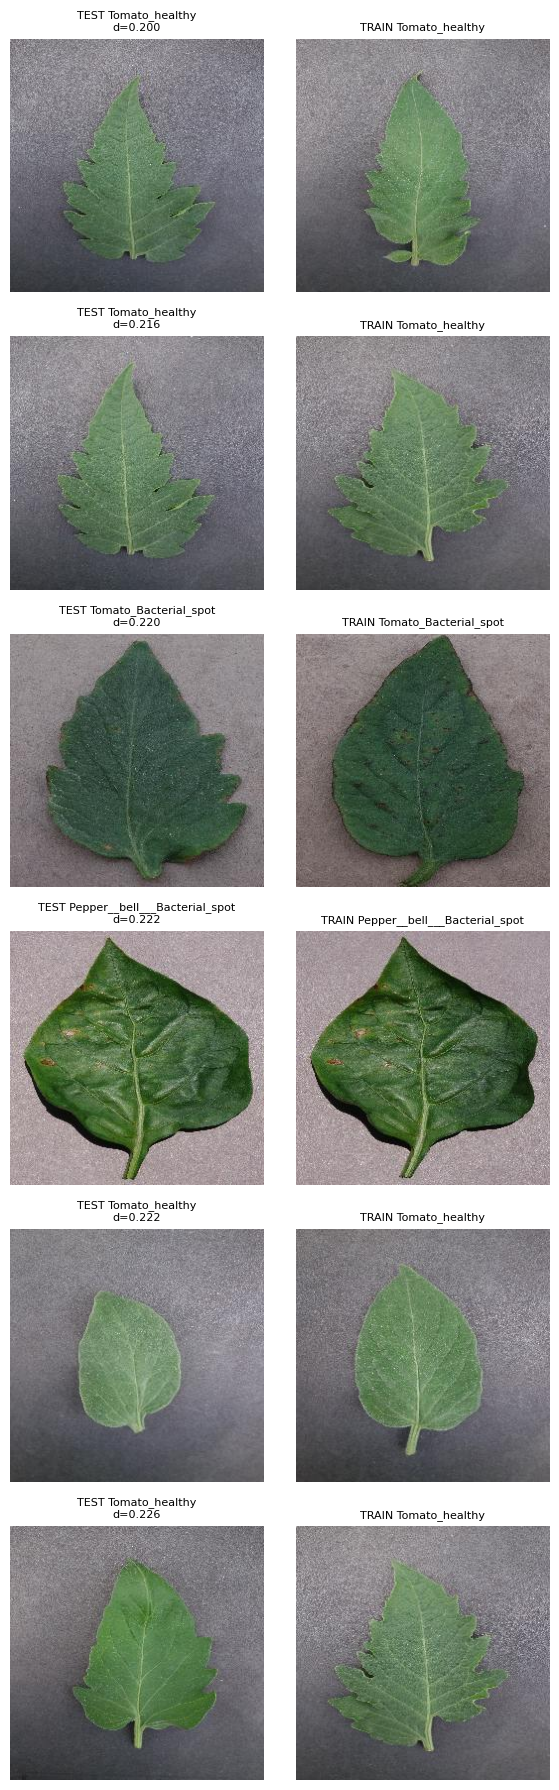

In [8]:
# Near-duplicate check between the carved splits (needed because TEST_DIR = None)
def fp_matrix(df):
    return torch.tensor(np.stack([fingerprint(p) for p in df['path']]),
                        dtype=torch.float32, device=device)

def nearest(A, B, chunk=512):
    """For each row of A: mean absolute difference to its closest row of B, and that row's index."""
    dists, idxs = [], []
    for i in range(0, len(A), chunk):
        d = torch.cdist(A[i:i + chunk], B, p=1) / A.shape[1]
        m, j = d.min(1)
        dists.append(m.cpu())
        idxs.append(j.cpu())
    return torch.cat(dists).numpy(), torch.cat(idxs).numpy()

t0 = time.time()
FP_tr, FP_va, FP_te = fp_matrix(tr_df), fp_matrix(va_df), fp_matrix(test_df)
print(f'Fingerprints done in {time.time() - t0:.0f}s')

d_te, j_te = nearest(FP_te, FP_tr)
d_va, j_va = nearest(FP_va, FP_tr)
near_te, near_va = d_te < 0.10, d_va < 0.10
print(f'Test images with a near-duplicate in train: {near_te.sum()} of {len(test_df)}')
print(f'Val images with a near-duplicate in train:  {near_va.sum()} of {len(va_df)}')
print('Closest test distances:', np.sort(d_te)[:10].round(3))

# Inspect the closest pairs BEFORE deleting anything
order = np.argsort(d_te)[:6]
fig, axes = plt.subplots(len(order), 2, figsize=(6, 3 * len(order)))
for r, k in enumerate(order):
    a, b = test_df.iloc[k], tr_df.iloc[j_te[k]]
    axes[r, 0].imshow(Image.open(a['path']).convert('RGB'))
    axes[r, 0].set_title(f"TEST {a['orig_class']}\nd={d_te[k]:.3f}", fontsize=8)
    axes[r, 1].imshow(Image.open(b['path']).convert('RGB'))
    axes[r, 1].set_title(f"TRAIN {b['orig_class']}", fontsize=8)
    axes[r, 0].axis('off')
    axes[r, 1].axis('off')
plt.tight_layout()
plt.show()

### Part 2 — Leakage audit

**Exact duplicates (MD5):** 28 files = **14 identical pairs**, all in Tomato_Late_blight and
Tomato_healthy. Every pair had the same label (0 conflicts) and the same file code, so it is
a storage duplication, not a labelling error. I removed the 14 extra copies (20,624 images remain).

**Group id discovery:** with my first regex (the code after `___`), every image was its own
group (**1.00 images per group**). Inspecting the duplicates, I found codes like
`GHLB Leaf 2.3 Day 13` — the same leaf photographed several times on several days.
I changed the regex to remove the shot number (`.3`) and the day (`Day 13`), so all photos
of one leaf share a group. Result: **1.02 images per group, 331 groups with more than one
photo**; the largest group (`GHLB Leaf 2`) has **16 photos** of one leaf from Day 1 to Day 16.

**Split:** train 14,324 | val 3,416 | test 2,884, built with StratifiedGroupKFold.
**Groups shared: train–val 0, train–test 0.**

**Near-duplicates (32×32 fingerprint):** **0 of 2,884** test images and **0 of 3,416** val images
have a near-duplicate in train. The closest distance was **0.20**, well above the ~0.12 of
genuinely different images. I inspected the six closest pairs: they are different leaves.

**What a random split would have done:** photos of the same leaf taken on consecutive days
would land in both train and test, so the model could recognise the individual leaf instead
of the disease. The test score would be inflated and would not reflect performance on new plants.

**Limitation:** most folders (e.g. `JR_B.Spot 8964`) carry no leaf id, so for them the split
is effectively per image. A true per-plant split is not possible with this dataset.

**Part 3:Transforms and immbalance**

In [9]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_rgb = [transforms.Grayscale(num_output_channels=3)] if GRAYSCALE else []

train_tf = transforms.Compose(to_rgb + [
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),   # no hue/saturation: colour is disease evidence
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose(to_rgb + [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ImageTable(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        self.y = df['label'].map({c: i for i, c in enumerate(classes)}).tolist()
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i])
        img = img.convert('L' if GRAYSCALE else 'RGB')
        return self.tf(img), self.y[i]

train_ds = ImageTable(tr_df, train_tf)
val_ds = ImageTable(va_df, eval_tf)
test_ds = ImageTable(test_df, eval_tf)
print(f'train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)}')
print('Class order:', classes)

train 14324 | val 3416 | test 2884
Class order: ['diseased', 'healthy']


In [10]:
n_c = np.bincount(train_ds.y, minlength=len(classes))
class_w = len(train_ds) / (len(classes) * n_c)        # N / (K * n_c)
print('Images per class in train:', dict(zip(classes, n_c)))
print('Class weights:', dict(zip(classes, class_w.round(3))))
loss_w = torch.tensor(class_w, dtype=torch.float32, device=device)

USE_SAMPLER = False     # try True later: balanced batches instead of weighted loss
if USE_SAMPLER:
    sample_w = class_w[train_ds.y]                     # P(i) ~ 1 / n_class(i)
    sampler = WeightedRandomSampler(sample_w, len(sample_w), replacement=True)
    train_dl = DataLoader(train_ds, 32, sampler=sampler, num_workers=2)
    loss_w = None
else:
    train_dl = DataLoader(train_ds, 32, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, 64, num_workers=2)
test_dl = DataLoader(test_ds, 64, num_workers=2)

Images per class in train: {'diseased': np.int64(12080), 'healthy': np.int64(2244)}
Class weights: {'diseased': np.float64(0.593), 'healthy': np.float64(3.192)}


### Part 3 — Transforms and imbalance

**Class weights** (formula N / (K × n_c), N = 14,324 training images, K = 2 classes):
- diseased: 14,324 / (2 × 12,080) = 14,324 / 24,160 = **0.593**
- healthy: 14,324 / (2 × 2,244) = 14,324 / 4,488 = **3.192**

Both match the printed weights. The healthy weight is 3.192 / 0.593 ≈ **5.4 times** the diseased
weight — exactly the imbalance ratio — so one mistake on a healthy leaf costs about as much in the
loss as five mistakes on diseased leaves. I used weighted cross-entropy (`USE_SAMPLER = False`).

**Augmentations (and why):**
- **Added horizontal and vertical flips:** unlike chest X-rays, a leaf has no fixed "up" or
  left/right, so a flipped leaf is still a realistic leaf.
- **Rotation raised from 10° to 20°:** leaves are placed on the cloth at different angles.
- **RandomResizedCrop (scale 0.8–1.0):** small changes in framing and distance. This also
  partly counters the framing shortcut from Part 1 (leaf size in the frame).
- **Brightness/contrast jitter kept mild (0.15):** lighting varies a little between photos.
- **No hue or saturation jitter:** yellowing and browning are the disease signal itself, so
  changing colour could make a healthy leaf look diseased.

**Part4:Training**

In [11]:
import glob

def find_weights(name):
    """Find a local .pth file for this backbone under /kaggle/input."""
    hits = [p for p in glob.glob('/kaggle/input/**/*.pth', recursive=True)
            if name.replace('_', '') in os.path.basename(p).lower().replace('_', '')]
    print('Weight files found:', hits)
    return hits[0] if hits else None

def load_local(m, path):
    """Load an old-format .pth file into model m and report any mismatch."""
    obj = torch.load(path, map_location='cpu', weights_only=False)
    if isinstance(obj, nn.Module):                 # file holds a whole model
        obj = obj.state_dict()
    if isinstance(obj, dict) and 'state_dict' in obj:
        obj = obj['state_dict']
    obj = {k.replace('module.', ''): v for k, v in obj.items()}
    result = m.load_state_dict(obj, strict=False)
    print('Missing keys:', result.missing_keys)
    print('Unexpected keys:', result.unexpected_keys)
    return m

def build_model(name, n_classes):
    if name == 'resnet18':
        local = find_weights('resnet18')
        if local:
            m = load_local(models.resnet18(weights=None), local)
        else:
            m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'resnet50':
        local = find_weights('resnet50')
        if local:
            m = load_local(models.resnet50(weights=None), local)
        else:
            m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'efficientnet_b0':
        local = find_weights('efficientnet_b0')
        if local:
            m = load_local(models.efficientnet_b0(weights=None), local)
        else:
            m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)
        body, head, last = m, m.classifier, m.features[-1]
    else:
        raise ValueError(name)
    for p in body.parameters():
        p.requires_grad = False
    for p in head.parameters():
        p.requires_grad = True
    return m.to(device), head, last

model, head, last_block = build_model(BACKBONE, len(classes))
print(BACKBONE, 'trainable:',
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Weight files found: ['/kaggle/input/datasets/pvlima/pretrained-pytorch-models/resnet18-5c106cde.pth', '/kaggle/input/datasets/amanriaz749/resn18/resnet18-f37072fd (3).pth']
Missing keys: []
Unexpected keys: []
resnet18 trainable: 1026


In [13]:
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(F.softmax(model(xb.to(device)), 1).cpu())
            ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

def fit(model, params, epochs, lr):
    opt = torch.optim.Adam(params, lr=lr)
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb, weight=loss_w)
            opt.zero_grad()
            loss.backward()
            opt.step()
        p, y = predict(model, val_dl)
        macro = f1_score(y, p.argmax(1), average='macro')      # not accuracy
        if macro > best:
            best, best_state = macro, copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: val macro-F1 {macro:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)
    return best

print('Phase 1: head only')
fit(model, head.parameters(), epochs=2, lr=1e-3)
print('Phase 2: fine-tune the last block')
for p in last_block.parameters():
    p.requires_grad = True
fit(model, [{'params': last_block.parameters(), 'lr': 1e-4},
            {'params': head.parameters(), 'lr': 1e-3}], epochs=3, lr=1e-3)

Phase 1: head only
epoch 1: val macro-F1 0.913 (45s)
epoch 2: val macro-F1 0.927 (49s)
Phase 2: fine-tune the last block
epoch 1: val macro-F1 0.977 (47s)
epoch 2: val macro-F1 0.992 (49s)
epoch 3: val macro-F1 0.987 (48s)


0.991657243617767

### Part 4 — Training

| Phase | Epoch | Val macro-F1 | Time |
|---|---|---|---|
| 1 – head only | 1 | 0.913 | 45 s |
| 1 – head only | 2 | 0.927 | 49 s |
| 2 – fine-tune layer4 | 1 | 0.977 | 47 s |
| 2 – fine-tune layer4 | 2 | **0.992** | 49 s |
| 2 – fine-tune layer4 | 3 | 0.987 | 48 s |

**Phase 1 (head only):** best validation macro-F1 **0.927**. Only the new 2-class layer
(1,026 parameters) was trained, so the model relies on generic ImageNet features.

**Phase 2 (fine-tune the last block):** best validation macro-F1 **0.992**.

**Did fine-tuning help?** Yes, clearly: macro-F1 rose from 0.927 to 0.992. Unfreezing `layer4`
let the model adapt its high-level features to leaf texture, spots and discolouration, which
ImageNet features do not capture well on their own.

**Model selection:** the best epoch (Phase 2, epoch 2, macro-F1 0.992) was restored at the end.
Epoch 3 dropped slightly to 0.987, a possible first sign of overfitting, which shows why the
best epoch must be chosen on validation macro-F1 rather than simply keeping the last epoch.

**Time per epoch:** about **48 seconds** on a Kaggle T4 GPU (≈ 4 minutes for all 5 epochs).

**With more time I would:**
- run 5–10 more fine-tuning epochs with a learning-rate scheduler (e.g. reduce LR on plateau);
- also unfreeze `layer3` with a smaller learning rate;
- repeat training with `USE_SAMPLER = True` and compare macro-F1 with the weighted-loss run.

**Note on weights:** the notebook had no internet access, so the ImageNet-pretrained ResNet-18
weights were loaded from a local copy (`resnet18-5c106cde.pth`); all keys matched
(0 missing, 0 unexpected), so this is the same pretrained model.

              precision    recall  f1-score   support

    diseased      0.999     0.997     0.998      2442
     healthy      0.982     0.995     0.989       442

    accuracy                          0.997      2884
   macro avg      0.991     0.996     0.993      2884
weighted avg      0.997     0.997     0.997      2884

Macro-F1: 0.993


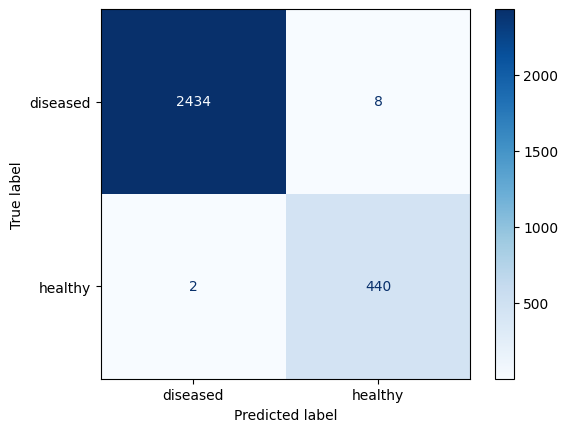

In [14]:
p_test, y_test = predict(model, test_dl)
pred = p_test.argmax(1)
print(classification_report(y_test, pred, target_names=classes, digits=3))
print('Macro-F1:', round(f1_score(y_test, pred, average='macro'), 3))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=classes).plot(cmap='Blues')
plt.show()

In [16]:
if len(classes) == 2:
    pos = classes.index(POSITIVE)
    p_val, y_val = predict(model, val_dl)
    fpr, tpr, thr = roc_curve(y_val == pos, p_val[:, pos])
    t = thr[np.argmax(tpr >= TARGET_RECALL)]     # highest t reaching target
    print(f'Threshold chosen on VALIDATION for recall >= {TARGET_RECALL}: '
          f'{t:.3f}')

    s = p_test[:, pos]
    yp, yt = s >= t, y_test == pos
    tp, fn = (yp & yt).sum(), (~yp & yt).sum()
    tn, fp = (~yp & ~yt).sum(), (yp & ~yt).sum()
    print(f'TP {tp} | FN {fn} | TN {tn} | FP {fp}')
    print(f'Test prevalence of {POSITIVE}: {yt.mean():.3f}')
    print(f'Test AUC {roc_auc_score(yt, s):.3f}')
    print(f'Sensitivity {tp / (tp + fn):.3f}   Specificity {tn / (tn + fp):.3f}'
          f'   PPV {tp / max(tp + fp, 1):.3f}')

Threshold chosen on VALIDATION for recall >= 0.95: 0.893
TP 2423 | FN 19 | TN 440 | FP 2
Test prevalence of diseased: 0.847
Test AUC 1.000
Sensitivity 0.992   Specificity 0.995   PPV 0.999


### Part 5 — Test set (used once) and threshold

**Macro-F1 on test: 0.993.**

| Class | Precision | Recall | F1 | Support |
|---|---|---|---|---|
| diseased | 0.999 | 0.997 | 0.998 | 2,442 |
| healthy | 0.982 | 0.995 | 0.989 | 442 |

**Weakest class: healthy** (F1 0.989, precision 0.982) — a few diseased leaves were labelled
healthy. It is the smaller class (442 test images), so each error weighs more.

**Threshold for target recall:** chosen on the **validation** set for recall ≥ 0.95: **t = 0.893**,
then applied once to the test set.

| | Predicted diseased | Predicted healthy |
|---|---|---|
| **Actually diseased** | TP = 2,423 | FN = 19 |
| **Actually healthy** | FP = 2 | TN = 440 |

- Sensitivity = 2,423 / (2,423 + 19) = **0.992**
- Specificity = 440 / (440 + 2) = **0.995**
- PPV = 2,423 / (2,423 + 2) = **0.999**
- Test AUC = **1.000**

**Did test recall reach the target?** Yes: 0.992 ≥ 0.95.

**Observation on the threshold:** the target was easy to reach, so the code chose a high threshold
(0.893). At this threshold 19 diseased leaves were missed — more than with the default argmax
(recall 0.997). For a farmer, missing a disease costs more than a false alarm, so a lower
threshold would be the better practical choice.

**AUC 1.000 is a warning sign:** perfect separation is rare on real data and suggests the lab
conditions make the task easier than in a real field (checked with Grad-CAM in Part 6).

### PPV at two prevalences (by hand)

PPV = (Sens × p) / (Sens × p + (1 − Spec) × (1 − p)), with Sens = 0.992, Spec = 0.995

**1. Test-set prevalence, p = 0.847** (2,442 of 2,884 test images are diseased):
- Sens × p = 0.992 × 0.847 = 0.8402
- (1 − Spec) × (1 − p) = 0.005 × 0.153 = 0.000765
- PPV = 0.8402 / (0.8402 + 0.000765) = 0.8402 / 0.8410 = **0.999** (matches the code)

**2. Realistic prevalence, p = 0.10** (routine field scouting, where roughly 1 in 10 leaves is diseased):
- Sens × p = 0.992 × 0.10 = 0.0992
- (1 − Spec) × (1 − p) = 0.005 × 0.90 = 0.0045
- PPV = 0.0992 / (0.0992 + 0.0045) = 0.0992 / 0.1037 = **0.957**

**In plain language:** in the test set, 85% of leaves are diseased, so when the model says
"diseased" it is almost always right. In a real field where only 10% of leaves are diseased,
healthy leaves are the large majority, so even a small 0.5% false-alarm rate on them produces
noticeable false alarms: about 4 of every 100 "diseased" alerts would be wrong. The model did not
change; only the mix of leaves did. Specificity also rests on just 442 healthy test images, so
this estimate is uncertain.

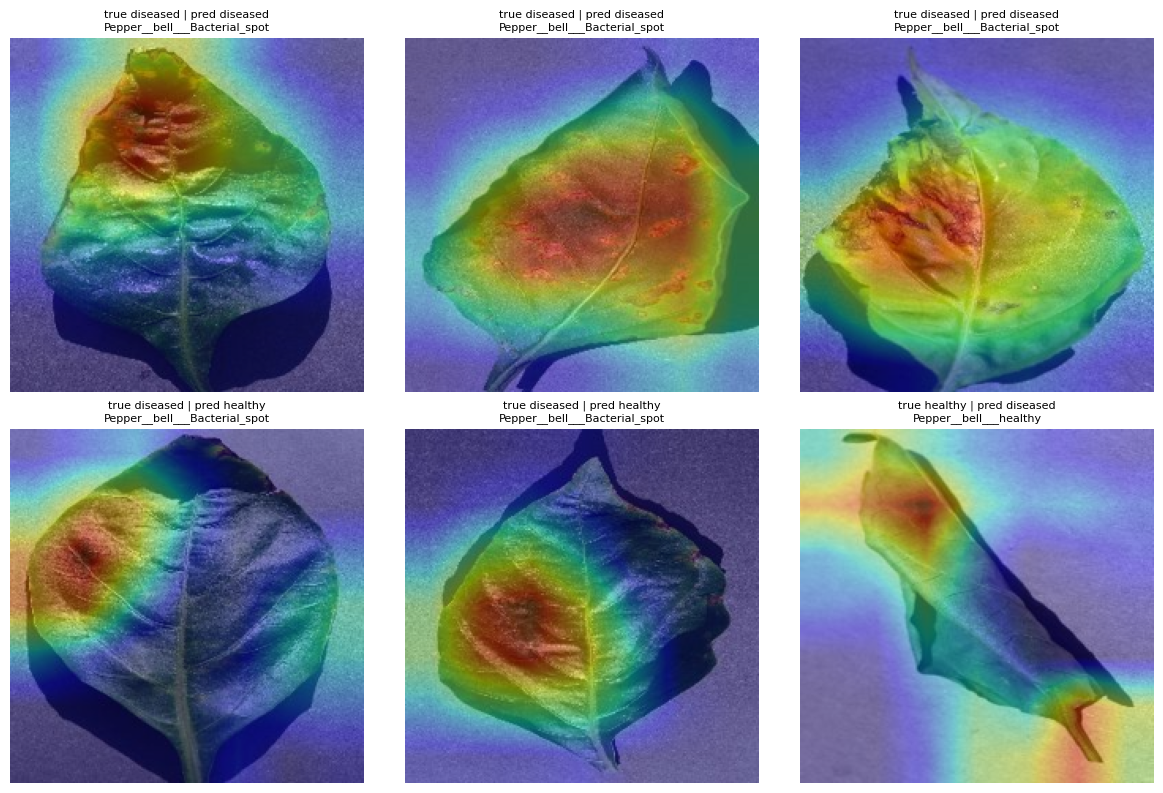

In [17]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._save_act)
        layer.register_full_backward_hook(self._save_grad)
    def _save_act(self, m, i, o):
        self.acts = o.detach()
    def _save_grad(self, m, gi, go):
        self.grads = go[0].detach()
    def __call__(self, x, cls=None):
        self.model.eval()
        x = x.unsqueeze(0).to(device).requires_grad_(True)
        logits = self.model(x)
        cls = int(logits.argmax()) if cls is None else cls
        self.model.zero_grad()
        logits[0, cls].backward()
        alpha = self.grads.mean(dim=(2, 3), keepdim=True)      # (1/Z) sum dy/dA
        cam = F.relu((alpha * self.acts).sum(1)).squeeze()     # ReLU(sum a*A)
        cam = F.interpolate(cam[None, None], size=x.shape[-2:],
                            mode='bilinear').squeeze()
        return (cam / (cam.max() + 1e-8)).cpu().numpy(), cls

for p in model.parameters():
    p.requires_grad = True
cam = GradCAM(model, last_block)
wrong = np.where(pred != y_test)[0][:3].tolist()
right = np.where(pred == y_test)[0][:3].tolist()
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, i in zip(axes.flat, right + wrong):
    x, y = test_ds[i]
    heat, c = cam(x)
    img = Image.open(test_ds.paths[i]).convert('RGB').resize((IMG_SIZE,) * 2)
    ax.imshow(img)
    ax.imshow(heat, cmap='jet', alpha=0.4)
    ax.set_title(f'true {classes[y]} | pred {classes[c]}\n{test_df.orig_class[i]}', fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

### Part 6 (continued) — Grad-CAM across all three crops

Because the first Grad-CAM cell showed only pepper leaves, I picked one correct example from each
crop and three random wrong predictions.

**Correct predictions:**
1. Pepper healthy → healthy: heat along the midrib and veins of the leaf — **legitimate**
   (healthy leaf structure).
2. Potato late blight → diseased: heat on the dark lesion area in the lower half of the leaf —
   **legitimate**.
3. Tomato spider mites → diseased: heat on the speckled, discoloured centre of the leaf —
   **legitimate**.

**Wrong predictions:**
4. Tomato late blight → predicted healthy: the heat is almost entirely on the **empty background**
   on the left side of the image; the shrivelled, diseased leaf on the right gets almost no
   attention — **not legitimate**. This is the clearest shortcut example in my notebook.
5. Pepper bacterial spot → predicted healthy: heat on one dark patch at the left edge of the leaf,
   while the rest of the leaf is ignored — the model missed the wider infection.
6. Pepper healthy → predicted diseased: heat on a shadowed fold of the leaf and spreading onto the
   background — **not legitimate**; shadow or background likely triggered the error.

**Updated verdict: shortcut strongly suspected.** On correct predictions the model looks at real
leaf evidence in all three crops. But two of the six wrong predictions (4 and 6), plus one in the
first Grad-CAM cell, put most of their attention on the background. Errors happen exactly when the
model looks off the leaf. This is not yet *confirmed*: the background-only test described above
would confirm it.

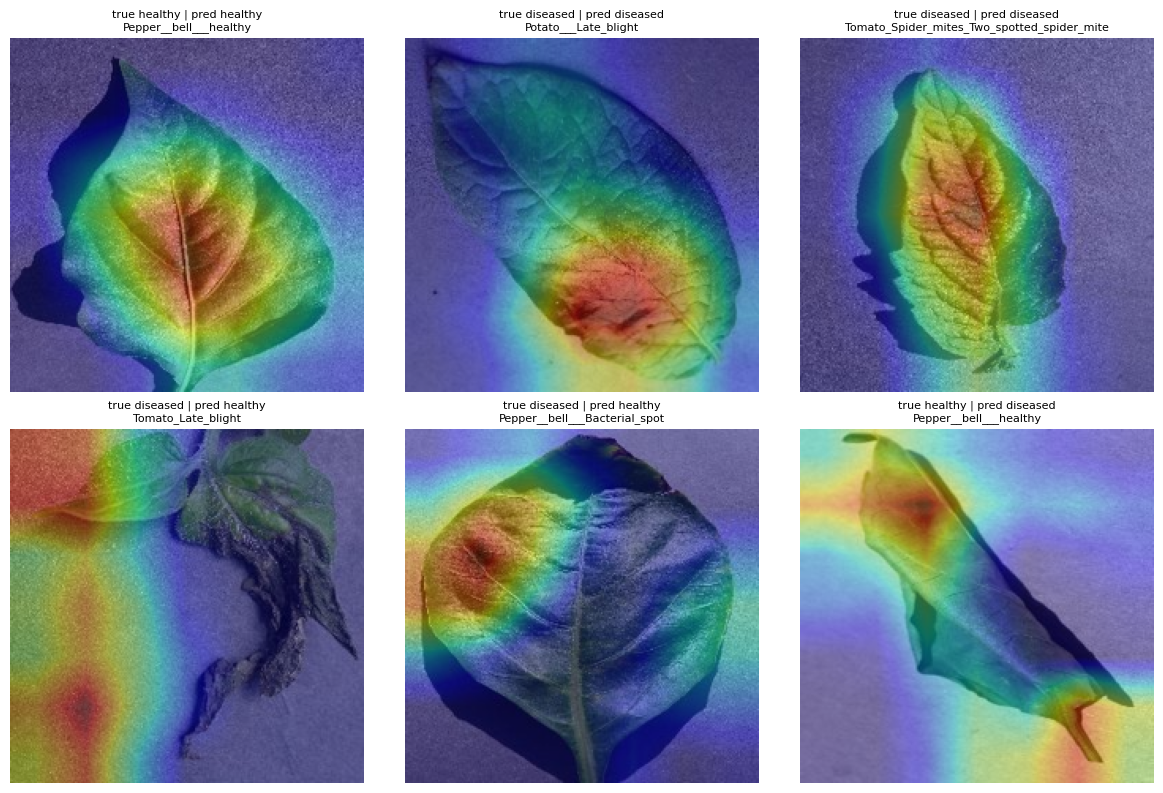

In [18]:
rng = np.random.default_rng(0)
crop = test_df['orig_class'].str.split('_').str[0].values
right_pool = np.where(pred == y_test)[0]
wrong_pool = np.where(pred != y_test)[0]
right = [int(rng.choice(right_pool[crop[right_pool] == c])) for c in ['Pepper', 'Potato', 'Tomato']]
wrong = rng.choice(wrong_pool, size=min(3, len(wrong_pool)), replace=False).tolist()

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, i in zip(axes.flat, right + wrong):
    x, y = test_ds[i]
    heat, c = cam(x)
    img = Image.open(test_ds.paths[i]).convert('RGB').resize((IMG_SIZE,) * 2)
    ax.imshow(img)
    ax.imshow(heat, cmap='jet', alpha=0.4)
    ax.set_title(f'true {classes[y]} | pred {classes[c]}\n{test_df.orig_class[i]}', fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [19]:
torch.save({'state_dict': model.state_dict(), 'classes': classes,
            'backbone': BACKBONE, 'img_size': IMG_SIZE,
            'grayscale': GRAYSCALE}, '/kaggle/working/week6_model.pt')
print('Saved week6_model.pt')

Saved week6_model.pt


## Check Your Understanding

**1. Why does a random split of chest X-rays overestimate performance?**
One patient often has several X-rays. With a random split, images of the same patient land in both
train and test, so the model can recognise patient-specific features (anatomy, scanner, markers)
instead of pneumonia. The test set is then not truly unseen, so the score is too high. I saw the same
risk in my own data: up to 16 photos of one leaf.

**2. Two classes have 900 and 100 training images. Class weights with N / (K × n_c)?**
N = 1,000, K = 2
- Class with 900: 1,000 / (2 × 900) = 1,000 / 1,800 = **0.556**
- Class with 100: 1,000 / (2 × 100) = 1,000 / 200 = **5.0**

**3. Focal loss with γ = 2: by what factor is an example with p_t = 0.8 down-weighted?**
Modulating factor = (1 − p_t)^γ = (1 − 0.8)² = 0.2² = 0.04
So the example is down-weighted by a factor of 1 / 0.04 = **25**.

**4. Sensitivity 0.90, specificity 0.95, prevalence 2%. Compute PPV.**
PPV = (0.90 × 0.02) / (0.90 × 0.02 + (1 − 0.95) × (1 − 0.02))
= 0.018 / (0.018 + 0.05 × 0.98)
= 0.018 / (0.018 + 0.049)
= 0.018 / 0.067 = **0.269 (about 27%)**
Only about 1 in 4 positive results is a true case, because the condition is rare.

**5. When is macro-F1 a better selection metric than weighted F1?**
When classes are imbalanced and the minority class matters as much as the majority. Weighted F1
weights each class by its size, so the majority class dominates and poor minority performance is
hidden. Macro-F1 averages the classes equally, so a model that ignores the minority class scores badly.

**6. Grad-CAM highlights a hospital label in the corner of X-rays. What do you do next?**
Treat it as a suspected shortcut and test it: mask or crop out the label region in the test images and
re-score, and check whether the label type or hospital correlates with the class. If performance
drops, the shortcut is confirmed: remove or mask the labels in all images, retrain, re-run Grad-CAM,
and report the corrected results together with this limitation.

### Changes from the lab framework (and why)

The lab says to adjust the framework for your own domain and justify it. These are my changes:

- **Configuration:** added `BINARY = True` to merge the 15 PlantVillage folders into
  *healthy* vs *diseased*; wrote my own `GROUP_PATTERN` for PlantVillage file names (it removes the
  shot number and day so all photos of one leaf share a group); `TEST_DIR = None` because the
  dataset has no test folder.
- **`index_folder`:** maps each folder to the binary label and keeps the original folder name
  (`orig_class`) for the audit.
- **Extra cells in Part 2:** a group check (to confirm the leaf grouping works), extra prints in the
  MD5 cell, a cell that removes the 14 exact duplicate copies, and a train–test shared-groups check.
- **Near-duplicate check:** the lab version only runs when a test folder exists, so I wrote a version
  that runs after the grouped split, comparing val and test against train on the GPU.
- **Augmentation:** added horizontal and vertical flips and raised rotation to 20°, because a leaf,
  unlike a chest X-ray, has no fixed orientation. No hue/saturation jitter, because colour is disease
  evidence.
- **Model loading:** Kaggle had no internet access in my session, so the ImageNet ResNet-18 weights are
  loaded from a local `.pth` file (all keys matched: 0 missing, 0 unexpected).
- **Threshold cell:** prints TP/FN/TN/FP and test prevalence to support the PPV hand calculation.
- **Grad-CAM:** the title also shows the original folder, and an extra cell shows examples from all
  three crops, because the first cell showed only pepper leaves.

Training, test evaluation and model saving follow the lab code unchanged.